In [20]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.spatial import ConvexHull                                                                ### PLOTTING

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            root / "Code" / "Code_AR_processes",
            root,
        )
        if (candidate / "functions.py").is_file()
        and (candidate / "plotting_functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError(
        "Could not locate Code/Code_AR_processes from the current directory."
    )
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

AR_IMAGES_DIR = AR_CODE_DIR / "outputs" / "images"                                                  ### PLOTTING
EXPERIMENT_OVERVIEWS_DIR = AR_IMAGES_DIR / "experiment_overviews"                                   ### PLOTTING
ORDER_SELECTION_IMAGES_DIR = AR_IMAGES_DIR / "order_selection"                                      ### PLOTTING
AR_IMAGE_DIRECTORIES = [                                                                            ### PLOTTING
    EXPERIMENT_OVERVIEWS_DIR,                                                                       ### PLOTTING
    *(ORDER_SELECTION_IMAGES_DIR / name for name in ("ar2", "cross_process")),                      ### PLOTTING
]                                                                                                   ### PLOTTING
for image_directory in AR_IMAGE_DIRECTORIES:                                                        ### PLOTTING
    image_directory.mkdir(parents=True, exist_ok=True)                                              ### PLOTTING

plt.style.use(style="seaborn-v0_8-whitegrid")                                                       ### PLOTTING
np.set_printoptions(precision=4, suppress=True)                                                     ### REPORTING


In [21]:
import importlib

from Code.Code_AR_processes import functions as ar_functions

ar_functions = importlib.reload(ar_functions)

from Code.Code_AR_processes.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
    ar_impulse_response,
    projected_subgradient_empirical_width,
    batched_geometric_width_curves,
    theoretical_ar_width_in_direction,
    population_minimizing_ar2_direction,
    vanishing_tie_breaking_selector,
    aic_bic_ar_order,
    pacf_cutoff_order,
    theoretical_width_2d_from_angle,
    ar_window_zonotope_generators,
    zonotope_polygon_2d,
    fibonacci_sphere_directions,
    zonotope_support_points,
)

phi: [-1.0876 -0.9523]


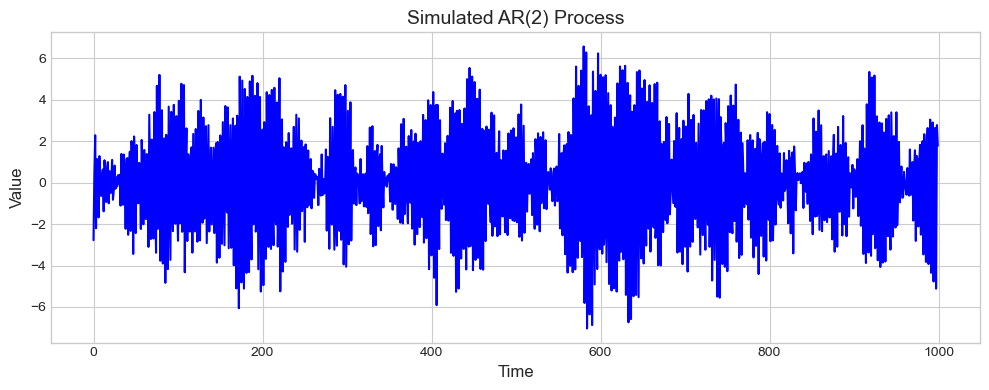

In [22]:
p = 2
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)                                                                                  ### REPORTING

fig, ax = plt.subplots(figsize=(10, 4))                                                             ### PLOTTING
ax.plot(ar_series, color="blue", linewidth=1.5)                                                     ### PLOTTING
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)                                             ### PLOTTING
ax.set_xlabel("Time", fontsize=12)                                                                  ### PLOTTING
ax.set_ylabel("Value", fontsize=12)                                                                 ### PLOTTING
plt.tight_layout()                                                                                  ### PLOTTING
plt.show()                                                                                          ### PLOTTING

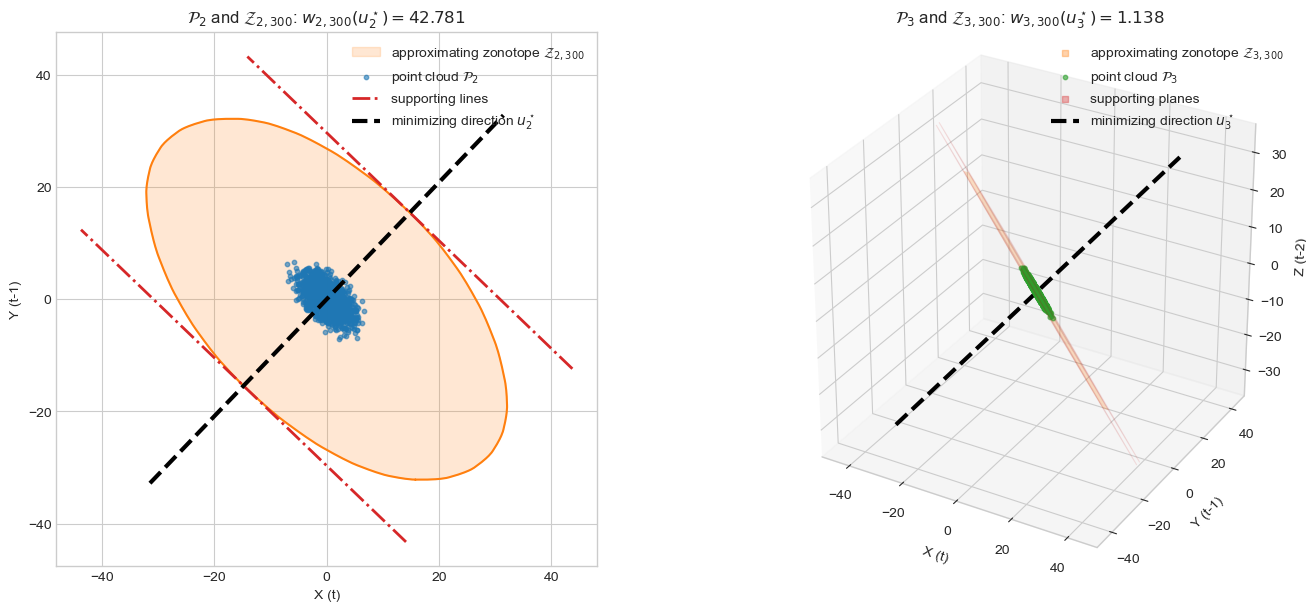

In [23]:
cloud_2d = sliding_window_point_cloud(ar_series, embedding_dimension=2)
cloud_3d = sliding_window_point_cloud(ar_series, embedding_dimension=3)

subgradient_2d = projected_subgradient_empirical_width(
    cloud_2d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260806,
)
subgradient_3d = projected_subgradient_empirical_width(
    cloud_3d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260807,
)

theoretical_history = 10_000
psi_for_cloud_plot = ar_impulse_response(phi, theoretical_history)
psi_shifted_once = np.concatenate(([0.0], psi_for_cloud_plot[:-1]))

angle_grid = np.linspace(0.0, np.pi, 721, endpoint=False)
width_grid = np.array([
    theoretical_width_2d_from_angle(
        angle, psi_for_cloud_plot, psi_shifted_once,
        innovations_half_width,
    )
    for angle in angle_grid
])
best_grid_angle = angle_grid[np.argmin(width_grid)]
theoretical_fit_2d = minimize(
    lambda angle: theoretical_width_2d_from_angle(
        float(angle[0]), psi_for_cloud_plot, psi_shifted_once,
        innovations_half_width,
    ),
    x0=np.array([best_grid_angle]),
    method="Nelder-Mead",
    options={"xatol": 1e-12, "fatol": 1e-12},
)
theoretical_angle_2d = float(theoretical_fit_2d.x[0] % np.pi)
theoretical_direction_2d = np.array([
    np.cos(theoretical_angle_2d),
    np.sin(theoretical_angle_2d),
])
theoretical_minimum_width_2d = theoretical_width_2d_from_angle(
    theoretical_angle_2d, psi_for_cloud_plot, psi_shifted_once,
    innovations_half_width,
)

theoretical_direction_3d = np.concatenate(([1.0], -phi))
theoretical_direction_3d /= np.linalg.norm(theoretical_direction_3d)
generator_projections_3d = np.convolve(
    psi_for_cloud_plot, theoretical_direction_3d
)[: theoretical_history + 1]
theoretical_minimum_width_3d = float(
    2.0 * innovations_half_width * np.sum(np.abs(generator_projections_3d))
)

# Use a finite impulse-response history to obtain drawable approximations                           ### PLOTTING
# Z_(k,H) of the infinite theoretical support zonotopes.                                            ### PLOTTING
zonotope_history = 300                                                                              ### PLOTTING

generators_2d = ar_window_zonotope_generators(                                                      ### PLOTTING
    phi, 2, zonotope_history, innovations_half_width                                                ### PLOTTING
)                                                                                                   ### PLOTTING
generators_3d = ar_window_zonotope_generators(                                                      ### PLOTTING
    phi, 3, zonotope_history, innovations_half_width                                                ### PLOTTING
)                                                                                                   ### PLOTTING
zonotope_vertices_2d = zonotope_polygon_2d(generators_2d)                                           ### PLOTTING

sphere_directions = fibonacci_sphere_directions(1_200)                                              ### PLOTTING
sphere_directions = np.vstack((                                                                     ### PLOTTING
    sphere_directions,                                                                              ### PLOTTING
    theoretical_direction_3d,                                                                       ### PLOTTING
    -theoretical_direction_3d,                                                                      ### PLOTTING
))                                                                                                  ### PLOTTING
zonotope_surface_points_3d = zonotope_support_points(                                               ### PLOTTING
    generators_3d, sphere_directions                                                                ### PLOTTING
)                                                                                                   ### PLOTTING
zonotope_hull_3d = ConvexHull(zonotope_surface_points_3d)                                           ### PLOTTING

# The two support levels are +/-h, so their separation is the finite-history width 2h.              ### PLOTTING
support_half_width_2d = np.sum(                                                                     ### PLOTTING
    np.abs(generators_2d.T @ theoretical_direction_2d)                                              ### PLOTTING
)                                                                                                   ### PLOTTING
support_half_width_3d = np.sum(                                                                     ### PLOTTING
    np.abs(generators_3d.T @ theoretical_direction_3d)                                              ### PLOTTING
)                                                                                                   ### PLOTTING
approximating_width_2d = 2.0 * support_half_width_2d                                                ### PLOTTING
approximating_width_3d = 2.0 * support_half_width_3d                                                ### PLOTTING

perpendicular_2d = np.array([                                                                       ### PLOTTING
    -theoretical_direction_2d[1], theoretical_direction_2d[0]                                       ### PLOTTING
])                                                                                                  ### PLOTTING
perpendicular_coordinates_2d = zonotope_vertices_2d @ perpendicular_2d                              ### PLOTTING
support_line_coordinate = np.linspace(                                                              ### PLOTTING
    perpendicular_coordinates_2d.min(),                                                             ### PLOTTING
    perpendicular_coordinates_2d.max(),                                                             ### PLOTTING
    2,                                                                                              ### PLOTTING
)                                                                                                   ### PLOTTING

reference_axis = np.array([0.0, 0.0, 1.0])                                                          ### PLOTTING
if abs(theoretical_direction_3d @ reference_axis) > 0.9:                                            ### PLOTTING
    reference_axis = np.array([0.0, 1.0, 0.0])                                                      ### PLOTTING
plane_basis_1 = np.cross(theoretical_direction_3d, reference_axis)                                  ### PLOTTING
plane_basis_1 /= np.linalg.norm(plane_basis_1)                                                      ### PLOTTING
plane_basis_2 = np.cross(theoretical_direction_3d, plane_basis_1)                                   ### PLOTTING
plane_coordinate_1 = zonotope_surface_points_3d @ plane_basis_1                                     ### PLOTTING
plane_coordinate_2 = zonotope_surface_points_3d @ plane_basis_2                                     ### PLOTTING
plane_grid_1, plane_grid_2 = np.meshgrid(                                                           ### PLOTTING
    np.linspace(plane_coordinate_1.min(), plane_coordinate_1.max(), 2),                             ### PLOTTING
    np.linspace(plane_coordinate_2.min(), plane_coordinate_2.max(), 2),                             ### PLOTTING
)                                                                                                   ### PLOTTING

direction_half_length_2d = 0.5 * np.linalg.norm(np.ptp(zonotope_vertices_2d, axis=0))               ### PLOTTING
direction_endpoints_2d = np.outer(                                                                  ### PLOTTING
    [-direction_half_length_2d, direction_half_length_2d],                                          ### PLOTTING
    theoretical_direction_2d,                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
direction_half_length_3d = 0.5 * np.linalg.norm(                                                    ### PLOTTING
    np.ptp(zonotope_surface_points_3d, axis=0)                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
direction_endpoints_3d = np.outer(                                                                  ### PLOTTING
    [-direction_half_length_3d, direction_half_length_3d],                                          ### PLOTTING
    theoretical_direction_3d,                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING

fig = plt.figure(figsize=(14, 6), constrained_layout=True)                                          ### PLOTTING
ax_2d = fig.add_subplot(1, 2, 1)                                                                    ### PLOTTING
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')                                                   ### PLOTTING
ax_2d.fill(                                                                                         ### PLOTTING
    zonotope_vertices_2d[:, 0],                                                                     ### PLOTTING
    zonotope_vertices_2d[:, 1],                                                                     ### PLOTTING
    color="tab:orange",                                                                             ### PLOTTING
    alpha=0.18,                                                                                     ### PLOTTING
    label=fr"approximating zonotope $\mathcal{{Z}}_{{2,{zonotope_history}}}$",                      ### PLOTTING
)                                                                                                   ### PLOTTING
ax_2d.plot(                                                                                         ### PLOTTING
    zonotope_vertices_2d[:, 0],                                                                     ### PLOTTING
    zonotope_vertices_2d[:, 1],                                                                     ### PLOTTING
    color="tab:orange",                                                                             ### PLOTTING
    linewidth=1.5,                                                                                  ### PLOTTING
)                                                                                                   ### PLOTTING
ax_2d.scatter(                                                                                      ### PLOTTING
    cloud_2d[:, 0], cloud_2d[:, 1],                                                                 ### PLOTTING
    color="tab:blue", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_2$"                         ### PLOTTING
)                                                                                                   ### PLOTTING
for support_sign in (-1.0, 1.0):                                                                    ### PLOTTING
    support_line = (                                                                                ### PLOTTING
        support_sign * support_half_width_2d * theoretical_direction_2d                             ### PLOTTING
        + np.outer(support_line_coordinate, perpendicular_2d)                                       ### PLOTTING
    )                                                                                               ### PLOTTING
    ax_2d.plot(                                                                                     ### PLOTTING
        support_line[:, 0], support_line[:, 1],                                                     ### PLOTTING
        color="tab:red", linestyle="-.", linewidth=2.0,                                             ### PLOTTING
        label="supporting lines" if support_sign < 0 else None,                                     ### PLOTTING
    )                                                                                               ### PLOTTING
ax_2d.plot(                                                                                         ### PLOTTING
    direction_endpoints_2d[:, 0],                                                                   ### PLOTTING
    direction_endpoints_2d[:, 1],                                                                   ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=3,                                                                                    ### PLOTTING
    label=r"minimizing direction $u_2^\star$",                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
ax_2d.set_title(                                                                                    ### PLOTTING
    rf"$\mathcal{{P}}_2$ and $\mathcal{{Z}}_{{2,{zonotope_history}}}$: "                            ### PLOTTING
    rf"$w_{{2,{zonotope_history}}}(u_2^\star)={approximating_width_2d:.3f}$",                       ### PLOTTING
    fontsize=12,                                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
ax_2d.set_xlabel("X (t)", fontsize=10)                                                              ### PLOTTING
ax_2d.set_ylabel("Y (t-1)", fontsize=10)                                                            ### PLOTTING
ax_2d.set_aspect("equal", adjustable="box")                                                         ### PLOTTING
ax_2d.legend(loc="upper right")                                                                     ### PLOTTING
ax_3d.plot_trisurf(                                                                                 ### PLOTTING
    zonotope_surface_points_3d[:, 0],                                                               ### PLOTTING
    zonotope_surface_points_3d[:, 1],                                                               ### PLOTTING
    zonotope_surface_points_3d[:, 2],                                                               ### PLOTTING
    triangles=zonotope_hull_3d.simplices,                                                           ### PLOTTING
    color="tab:orange", alpha=0.12, linewidth=0.15, shade=False,                                    ### PLOTTING
)                                                                                                   ### PLOTTING
ax_3d.scatter([], [], [], color="tab:orange", marker="s", alpha=0.35,                               ### PLOTTING
              label=fr"approximating zonotope $\mathcal{{Z}}_{{3,{zonotope_history}}}$")            ### PLOTTING
ax_3d.scatter(                                                                                      ### PLOTTING
    cloud_3d[:, 0], cloud_3d[:, 1], cloud_3d[:, 2],                                                 ### PLOTTING
    color="tab:green", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_3$"                        ### PLOTTING
)                                                                                                   ### PLOTTING
for support_sign in (-1.0, 1.0):                                                                    ### PLOTTING
    support_plane = (                                                                               ### PLOTTING
        support_sign * support_half_width_3d * theoretical_direction_3d                             ### PLOTTING
        + plane_grid_1[..., None] * plane_basis_1                                                   ### PLOTTING
        + plane_grid_2[..., None] * plane_basis_2                                                   ### PLOTTING
    )                                                                                               ### PLOTTING
    ax_3d.plot_surface(                                                                             ### PLOTTING
        support_plane[:, :, 0],                                                                     ### PLOTTING
        support_plane[:, :, 1],                                                                     ### PLOTTING
        support_plane[:, :, 2],                                                                     ### PLOTTING
        color="tab:red", alpha=0.12, edgecolor="tab:red", linewidth=0.8,                            ### PLOTTING
    )                                                                                               ### PLOTTING
ax_3d.scatter([], [], [], color="tab:red", marker="s", alpha=0.35,                                  ### PLOTTING
              label="supporting planes")                                                            ### PLOTTING
ax_3d.plot(                                                                                         ### PLOTTING
    direction_endpoints_3d[:, 0],                                                                   ### PLOTTING
    direction_endpoints_3d[:, 1],                                                                   ### PLOTTING
    direction_endpoints_3d[:, 2],                                                                   ### PLOTTING
    color="black",                                                                                  ### PLOTTING
    linestyle="--",                                                                                 ### PLOTTING
    linewidth=3,                                                                                    ### PLOTTING
    label=r"minimizing direction $u_3^\star$",                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
ax_3d.set_title(                                                                                    ### PLOTTING
    rf"$\mathcal{{P}}_3$ and $\mathcal{{Z}}_{{3,{zonotope_history}}}$: "                            ### PLOTTING
    rf"$w_{{3,{zonotope_history}}}(u_3^\star)={approximating_width_3d:.3f}$",                       ### PLOTTING
    fontsize=12,                                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
ax_3d.set_xlabel("X (t)", fontsize=10)                                                              ### PLOTTING
ax_3d.set_ylabel("Y (t-1)", fontsize=10)                                                            ### PLOTTING
ax_3d.set_zlabel("Z (t-2)", fontsize=10)                                                            ### PLOTTING
ax_3d.set_box_aspect(np.ptp(zonotope_surface_points_3d, axis=0))                                    ### PLOTTING
ax_3d.legend(loc="upper right")                                                                     ### PLOTTING
plt.show()                                                                                          ### PLOTTING

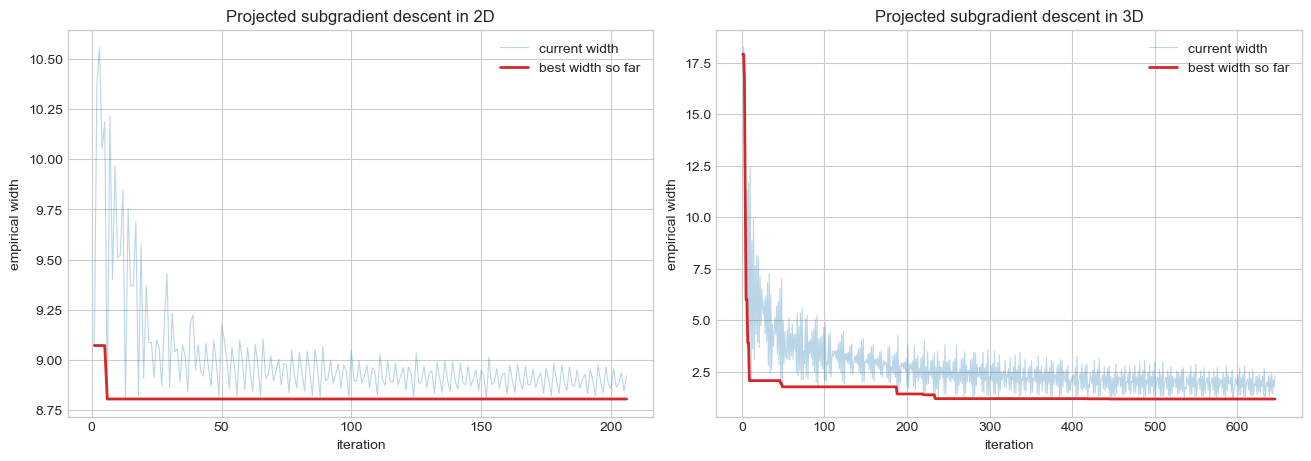

2D minimum width: 8.80492693993552
2D minimizing direction: [0.7341 0.6791]
3D minimum width: 1.1705339207686687
3D minimizing direction: [0.572  0.6177 0.5397]


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)                          ### PLOTTING

for axis, result, dimension in zip(                                                                 ### PLOTTING
    axes,                                                                                           ### PLOTTING
    (subgradient_2d, subgradient_3d),                                                               ### PLOTTING
    (2, 3),                                                                                         ### PLOTTING
):                                                                                                  ### PLOTTING
    iteration_numbers = np.arange(1, len(result["width_history"]) + 1)                              ### PLOTTING
    axis.plot(                                                                                      ### PLOTTING
        iteration_numbers,                                                                          ### PLOTTING
        result["width_history"],                                                                    ### PLOTTING
        color="tab:blue",                                                                           ### PLOTTING
        alpha=0.3,                                                                                  ### PLOTTING
        linewidth=0.8,                                                                              ### PLOTTING
        label="current width",                                                                      ### PLOTTING
    )                                                                                               ### PLOTTING
    axis.plot(                                                                                      ### PLOTTING
        iteration_numbers,                                                                          ### PLOTTING
        result["best_width_history"],                                                               ### PLOTTING
        color="tab:red",                                                                            ### PLOTTING
        linewidth=2.0,                                                                              ### PLOTTING
        label="best width so far",                                                                  ### PLOTTING
    )                                                                                               ### PLOTTING
    axis.set(                                                                                       ### PLOTTING
        title=f"Projected subgradient descent in {dimension}D",                                     ### PLOTTING
        xlabel="iteration",                                                                         ### PLOTTING
        ylabel="empirical width",                                                                   ### PLOTTING
    )                                                                                               ### PLOTTING
    axis.legend()                                                                                   ### PLOTTING

plt.show()                                                                                          ### PLOTTING

print("2D minimum width:", subgradient_2d["minimum_width"])                                         ### REPORTING
print("2D minimizing direction:", subgradient_2d["direction"])                                      ### REPORTING
print("3D minimum width:", subgradient_3d["minimum_width"])                                         ### REPORTING
print("3D minimizing direction:", subgradient_3d["direction"])                                      ### REPORTING


## Step-size schedule comparison

The following paired experiment compares the two schedules on the same simulated AR(2) series and the same initial directions. It uses five starts for each embedding dimension, 1,000 iterations, $\eta_0=0.2$, and $\beta=0.99$. Thus the only difference within each pair is

$$\eta_t=\frac{\eta_0}{\sqrt{t+1}} \qquad\text{or}\qquad \eta_t=\eta_0\beta^t.$$


In [25]:
from time import perf_counter
from IPython.display import display                                                                 ### REPORTING

schedule_comparison_dimensions = [2, 3, 5, 10, 25, 100]
schedule_comparison_starts = 5
schedule_comparison_iterations = 1_000
schedule_comparison_initial_step = 0.2
schedule_comparison_geometric_decay = 0.99
schedule_comparison_rng = np.random.default_rng(20260813)
schedule_comparison_rows = []

for dimension in schedule_comparison_dimensions:
    cloud = sliding_window_point_cloud(ar_series, dimension)
    initial_directions = schedule_comparison_rng.normal(
        size=(schedule_comparison_starts, dimension)
    )
    initial_directions /= np.linalg.norm(
        initial_directions, axis=1, keepdims=True
    )

    for start_index, initial_direction in enumerate(initial_directions):
        for step_schedule in ("inverse_sqrt", "geometric"):
            start_time = perf_counter()
            fit = projected_subgradient_empirical_width(
                cloud,
                iterations=schedule_comparison_iterations,
                initial_step=schedule_comparison_initial_step,
                step_schedule=step_schedule,
                geometric_decay=schedule_comparison_geometric_decay,
                patience=schedule_comparison_iterations,
                improvement_tolerance=0.0,
                initial_direction=initial_direction,
                rng=1_000 + dimension + start_index,
            )
            schedule_comparison_rows.append({
                "k": dimension,
                "start": start_index,
                "step_schedule": step_schedule,
                "minimum_width": fit["minimum_width"],
                "seconds": perf_counter() - start_time,
            })

schedule_comparison = pd.DataFrame(schedule_comparison_rows)
paired_widths = schedule_comparison.pivot(
    index=["k", "start"],
    columns="step_schedule",
    values="minimum_width",
)
median_widths = paired_widths.groupby(level="k").median()
schedule_comparison_summary = median_widths.copy()
schedule_comparison_summary["geometric_wins"] = (
    paired_widths["geometric"] < paired_widths["inverse_sqrt"]
).groupby(level="k").sum()
schedule_comparison_summary["relative_improvement_percent"] = (
    100.0
    * (schedule_comparison_summary["inverse_sqrt"]
       - schedule_comparison_summary["geometric"])
    / schedule_comparison_summary["inverse_sqrt"]
)

display(schedule_comparison_summary.round(6))                                                       ### REPORTING
print(                                                                                              ### REPORTING
    "Overall paired wins for the geometric schedule:",                                              ### REPORTING
    int((paired_widths["geometric"] < paired_widths["inverse_sqrt"]).sum()),                        ### REPORTING
    "out of",                                                                                       ### REPORTING
    len(paired_widths),                                                                             ### REPORTING
)                                                                                                   ### REPORTING


step_schedule,geometric,inverse_sqrt,geometric_wins,relative_improvement_percent
k,,,,
2,8.803711,8.803923,5,0.002415
3,1.136173,1.157649,5,1.855213
5,1.113758,1.328418,5,16.159066
10,1.153020,1.509784,5,23.630108
25,1.111650,1.809104,5,38.552473
100,1.250909,2.770756,5,54.853158


Overall paired wins for the geometric schedule: 30 out of 30


With seed 20260813, the geometric schedule won all 30 paired trials. The observed median minimum widths were:

| $k$ | Geometric | Inverse square root | Geometric wins |
|---:|---:|---:|---:|
| 2 | 8.803711 | 8.803923 | 5/5 |
| 3 | 1.136173 | 1.157649 | 5/5 |
| 5 | 1.113758 | 1.328418 | 5/5 |
| 10 | 1.153020 | 1.509784 | 5/5 |
| 25 | 1.111650 | 1.809104 | 5/5 |
| 100 | 1.250909 | 2.770756 | 5/5 |

For this fixed iteration budget and tuning, the geometric schedule is clearly better. Its faster decay allows fine local adjustments near a kink, whereas the inverse-square-root step is still approximately $0.0063$ at iteration 1,000 and continues to jump across the nonsmooth minimum. This is an empirical comparison, not a universal guarantee: Theorem 4 is local and its admissible values of $\eta_0$ and $\beta$ depend on the sharpness and initialization constants.


## Vanishing tie-breaking penalty for $p=1,2,3$: 50 processes per order

The selector minimizes a scale-free penalized width,

$$C_T(k)=\frac{\widehat m_k-\min_j\widehat m_j}{\max_j\widehat m_j-\min_j\widehat m_j}+\lambda_T\frac{k-1}{K-1},\qquad k=2,\ldots,K,$$

with $\lambda_T=T^{-1/4}$. At $T=2{,}000$, the total penalty difference across the full embedding range is approximately $0.1495$, or $0.0166$ per adjacent dimension when $K=10$. This choice is motivated by a provisional root-$T$ normalized estimation-error rate: $T^{-1/4}\to0$ but dominates $T^{-1/2}$. The normalization makes the penalty comparable across processes with very different width scales. Fifty new evaluations use the same fixed seed families and simulation settings as the preceding order-specific experiments.


Completed 10/50 AR(1) processes
Completed 20/50 AR(1) processes
Completed 30/50 AR(1) processes
Completed 40/50 AR(1) processes
Completed 50/50 AR(1) processes
Completed 10/50 AR(2) processes
Completed 20/50 AR(2) processes
Completed 30/50 AR(2) processes
Completed 40/50 AR(2) processes
Completed 50/50 AR(2) processes
Completed 10/50 AR(3) processes
Completed 20/50 AR(3) processes
Completed 30/50 AR(3) processes
Completed 40/50 AR(3) processes
Completed 50/50 AR(3) processes


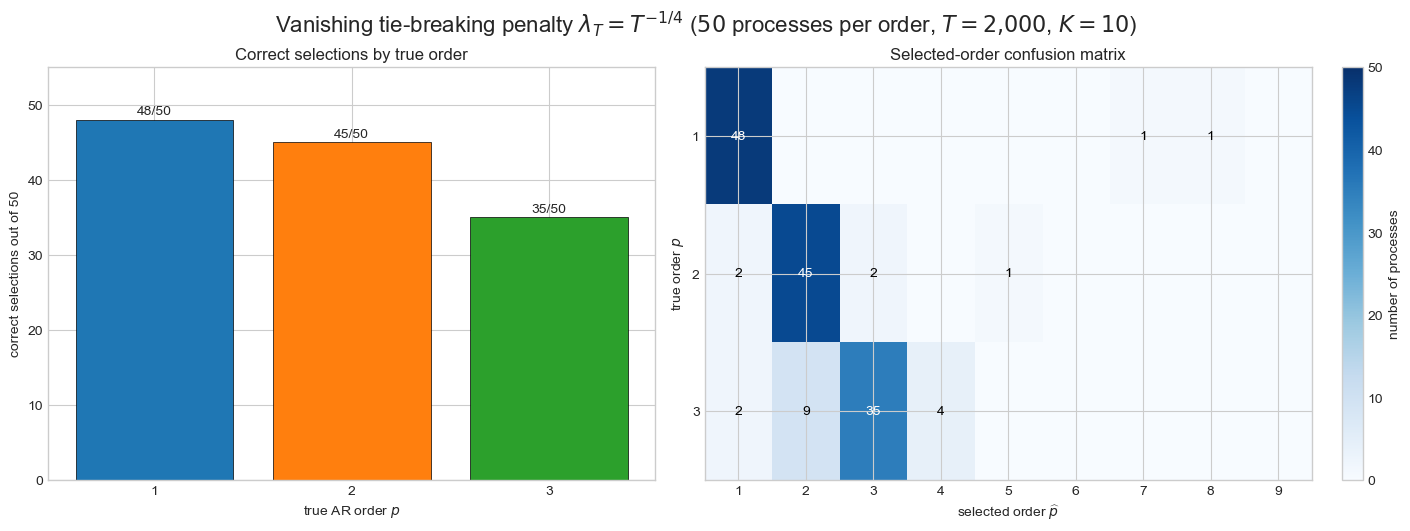

lambda_T = 0.14953487812212204
Correct selections out of 50
true_order
1    48
2    45
3    35
Selected-order confusion matrix
selected_order   1   2   3  4  5  6  7  8  9
true_order                                  
1               48   0   0  0  0  0  1  1  0
2                2  45   2  0  1  0  0  0  0
3                2   9  35  4  0  0  0  0  0


In [27]:
vanishing_penalty_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
vanishing_penalty_rows = []
vanishing_penalty_sample_size_T = 2_000
vanishing_penalty_k_values = np.arange(1, 11)
for setting in vanishing_penalty_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(50):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=vanishing_penalty_sample_size_T,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        _, minimized_widths, _ = batched_geometric_width_curves(
            series_replication,
            vanishing_penalty_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
            initial_step=0.2,
            geometric_decay=0.99,
        )
        selection = vanishing_tie_breaking_selector(
            vanishing_penalty_k_values, minimized_widths,
            vanishing_penalty_sample_size_T,
        )
        vanishing_penalty_rows.append({
            "true_order": true_order,
            "replication": replication + 1,
            "selected_q": selection["selected_q"],
            "selected_order": selection["selected_order"],
            "correct_order": selection["selected_order"] == true_order,
            "lambda_T": selection["lambda_T"],
        })
        if (replication + 1) % 10 == 0:                                                             ### REPORTING
            print(                                                                                  ### REPORTING
                f"Completed {replication + 1}/50 AR({true_order}) processes"                        ### REPORTING
            )                                                                                       ### REPORTING

vanishing_penalty_results = pd.DataFrame(vanishing_penalty_rows)
vanishing_penalty_accuracy = (
    vanishing_penalty_results.groupby("true_order")["correct_order"]
    .sum().reindex([1, 2, 3])
)
vanishing_penalty_confusion = pd.crosstab(
    vanishing_penalty_results["true_order"],
    vanishing_penalty_results["selected_order"],
).reindex(index=[1, 2, 3], columns=np.arange(1, 10), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)                          ### PLOTTING
axes[0].bar(                                                                                        ### PLOTTING
    vanishing_penalty_accuracy.index,                                                               ### PLOTTING
    vanishing_penalty_accuracy.values,                                                              ### PLOTTING
    color=["tab:blue", "tab:orange", "tab:green"],                                                  ### PLOTTING
    edgecolor="black", linewidth=0.5,                                                               ### PLOTTING
)                                                                                                   ### PLOTTING
for true_order, count in vanishing_penalty_accuracy.items():                                        ### PLOTTING
    axes[0].text(true_order, count + 0.7, f"{int(count)}/50", ha="center")                          ### PLOTTING
axes[0].set(                                                                                        ### PLOTTING
    title="Correct selections by true order",                                                       ### PLOTTING
    xlabel=r"true AR order $p$",                                                                    ### PLOTTING
    ylabel="correct selections out of 50",                                                          ### PLOTTING
    xticks=[1, 2, 3], ylim=(0, 55),                                                                 ### PLOTTING
)                                                                                                   ### PLOTTING

confusion_values = vanishing_penalty_confusion.to_numpy()                                           ### PLOTTING
image = axes[1].imshow(                                                                             ### PLOTTING
    confusion_values, cmap="Blues", vmin=0, vmax=50, aspect="auto"                                  ### PLOTTING
)                                                                                                   ### PLOTTING
for row in range(confusion_values.shape[0]):                                                        ### PLOTTING
    for column in range(confusion_values.shape[1]):                                                 ### PLOTTING
        value = confusion_values[row, column]                                                       ### PLOTTING
        if value:                                                                                   ### PLOTTING
            axes[1].text(                                                                           ### PLOTTING
                column, row, str(value), ha="center", va="center",                                  ### PLOTTING
                color="white" if value >= 25 else "black",                                          ### PLOTTING
            )                                                                                       ### PLOTTING
axes[1].set(                                                                                        ### PLOTTING
    title="Selected-order confusion matrix",                                                        ### PLOTTING
    xlabel=r"selected order $\widehat p$",                                                          ### PLOTTING
    ylabel=r"true order $p$",                                                                       ### PLOTTING
    xticks=np.arange(9), xticklabels=np.arange(1, 10),                                              ### PLOTTING
    yticks=np.arange(3), yticklabels=[1, 2, 3],                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
fig.colorbar(image, ax=axes[1], label="number of processes")                                        ### PLOTTING
fig.suptitle(                                                                                       ### PLOTTING
    rf"Vanishing tie-breaking penalty $\lambda_T=T^{{-1/4}}$ "                                      ### PLOTTING
    rf"($50$ processes per order, $T=2{{,}}000$, $K=10$)",                                          ### PLOTTING
    fontsize=16,                                                                                    ### PLOTTING
)                                                                                                   ### PLOTTING
vanishing_penalty_figure_path = (                                                                   ### PLOTTING
    ORDER_SELECTION_IMAGES_DIR / "cross_process" / "vanishing_penalty_p1_p2_p3_50_each_T2000.png"   ### PLOTTING
)                                                                                                   ### PLOTTING
fig.savefig(                                                                                        ### PLOTTING
    vanishing_penalty_figure_path, dpi=200, bbox_inches="tight"                                     ### PLOTTING
)                                                                                                   ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print("lambda_T =", vanishing_penalty_sample_size_T ** (-0.25))                                     ### REPORTING
print("Correct selections out of 50")                                                               ### REPORTING
print(vanishing_penalty_accuracy.to_string())                                                       ### REPORTING
print("Selected-order confusion matrix")                                                            ### REPORTING
print(vanishing_penalty_confusion.to_string())                                                      ### REPORTING


**Result.** With $\lambda_T=T^{-1/4}=0.1495$, the vanishing-penalty selector obtains 48/50 correct selections for AR(1), 45/50 for AR(2), and 35/50 for AR(3), or 128/150 (85.3%) overall. The AR(1) errors select orders 7 and 8. For AR(2), two processes are underestimated as order 1, two are overestimated as order 3, and one as order 5. For AR(3), two select order 1, nine select order 2, and four select order 4. The remaining AR(3) error pattern is primarily early selection, consistent with the positive increasing penalty. The numerical result is promising but the choice $T^{-1/4}$ remains provisional: a thesis consistency result would require a proved normalized error rate, and empirical reporting should include sensitivity to the multiplicative constant and new simulation seeds.


## One complete AR(2) minimum-width pipeline

This reproducible example generates one stationary AR(2) process with innovations $\varepsilon_t\sim\operatorname{Unif}[-1,1]$, computes $\widehat m_k$ for $k=1,\ldots,10$ using three-start projected subgradient descent, and applies the vanishing-penalty selector. The population minimum is displayed for $k\ge p+1=3$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2)\rVert_2$. Two cross-evaluated curves distinguish finite-sample width error from directional optimization error: $\widehat w_k(u_k^{\min})$ evaluates the empirical cloud in a population-minimizing direction, whereas $w_k(\widehat u_k)$ evaluates population width in the empirically minimizing direction. The $k=2$ population minimizer is obtained by one-dimensional numerical minimization.


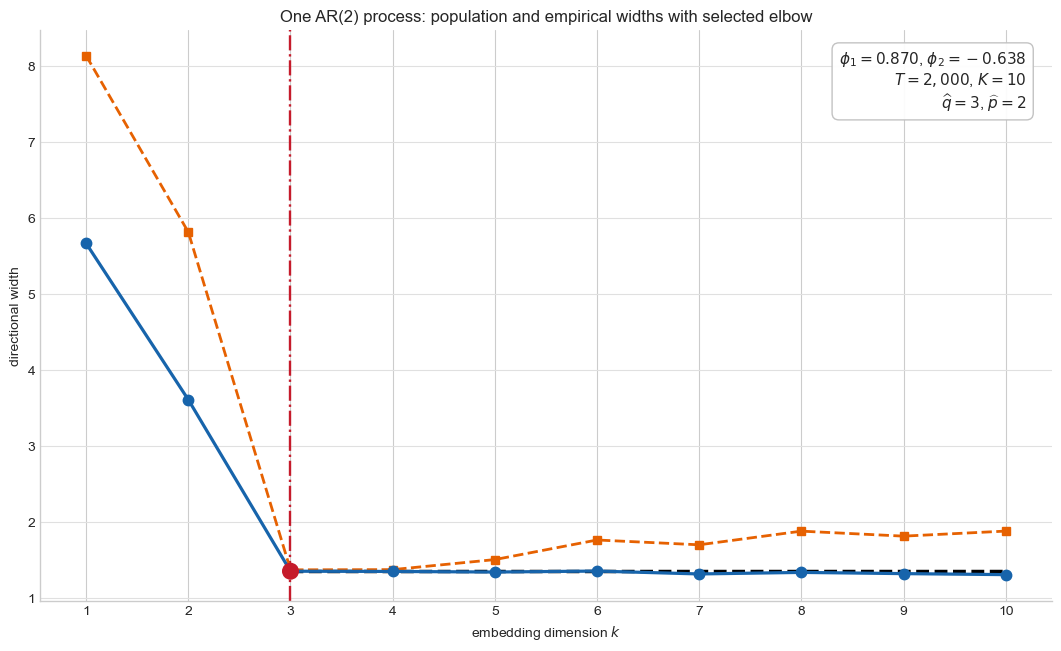

AR coefficients = [ 0.87   -0.6378]
Population plateau m* = 1.359696
Selected q = 3; selected AR order p = 2; lambda_T = 0.149535
 k  empirical_width  population_width  empirical_at_population_min  population_at_empirical_min  selection_criterion
 1         5.666273               NaN                     5.666273                     8.134278             1.000000
 2         3.611462               NaN                     3.742785                     5.814844             0.544791
 3         1.356190          1.359696                     1.358552                     1.374417             0.043552
 4         1.353215          1.359696                     1.358552                     1.377254             0.059484
 5         1.345548          1.359696                     1.358552                     1.509190             0.074338
 6         1.358174          1.359696                     1.358552                     1.766764             0.093853
 7         1.320195          1.359696              

In [28]:
single_ar2_seed = 20260814
single_ar2_replication = 1
single_ar2_T = 2_000
single_ar2_burnin = 1_000
single_ar2_k_values = np.arange(1, 11)
single_ar2_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar2_seed, single_ar2_replication, 0
]))
single_ar2_phi = jones_ar_coefficients(
    2, rng=single_ar2_generator
)
single_ar2_series = simulate_uniform_ar(
    single_ar2_phi, single_ar2_T, single_ar2_burnin, 1.0,
    rng=single_ar2_generator,
)
_, single_ar2_widths, _, single_ar2_empirical_directions = (
    batched_geometric_width_curves(
        single_ar2_series,
        single_ar2_k_values,
        seed=single_ar2_seed,
        replication=single_ar2_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar2_selection = vanishing_tie_breaking_selector(
    single_ar2_k_values, single_ar2_widths, single_ar2_T
)
single_ar2_q_hat = single_ar2_selection["selected_q"]
single_ar2_p_hat = single_ar2_selection["selected_order"]
single_ar2_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar2_phi]
)
single_ar2_population_directions = []
single_ar2_empirical_at_population_min = []
single_ar2_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar2_k_values, single_ar2_empirical_directions
):
    population_direction = population_minimizing_ar2_direction(
        single_ar2_phi, int(k)
    )
    cloud_k = sliding_window_point_cloud(single_ar2_series, int(k))
    single_ar2_population_directions.append(population_direction)
    single_ar2_empirical_at_population_min.append(
        np.ptp(cloud_k @ population_direction)
    )
    single_ar2_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar2_phi, empirical_direction, half_width=1.0
        )
    )
single_ar2_empirical_at_population_min = np.asarray(
    single_ar2_empirical_at_population_min
)
single_ar2_population_at_empirical_min = np.asarray(
    single_ar2_population_at_empirical_min
)

single_ar2_pipeline_results = pd.DataFrame({                                                        ### REPORTING
    "k": single_ar2_k_values,                                                                       ### REPORTING
    "empirical_width": single_ar2_widths,                                                           ### REPORTING
    "population_width": np.where(                                                                   ### REPORTING
        single_ar2_k_values >= 3, single_ar2_population_width, np.nan                               ### REPORTING
    ),                                                                                              ### REPORTING
    "empirical_at_population_min": (                                                                ### REPORTING
        single_ar2_empirical_at_population_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "population_at_empirical_min": (                                                                ### REPORTING
        single_ar2_population_at_empirical_min                                                      ### REPORTING
    ),                                                                                              ### REPORTING
    "selection_criterion": single_ar2_selection["criterion"],                                       ### REPORTING
})                                                                                                  ### REPORTING

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)                              ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values, single_ar2_widths, color="#1764ab",                                        ### PLOTTING
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,                                            ### PLOTTING
    label=r"empirical $\widehat m_k$",                                                              ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values[2:],                                                                        ### PLOTTING
    np.full(len(single_ar2_k_values) - 2, single_ar2_population_width),                             ### PLOTTING
    color="black", linestyle="--", linewidth=2.5, zorder=2,                                         ### PLOTTING
    label=r"population $m_k=m^*$ for $k\geq3$",                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.plot(                                                                                          ### PLOTTING
    single_ar2_k_values, single_ar2_population_at_empirical_min,                                    ### PLOTTING
    color="#e66101", marker="s", markersize=5.8,                                                    ### PLOTTING
    linestyle="--", linewidth=2.0, zorder=3,                                                        ### PLOTTING
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",                                 ### PLOTTING
)                                                                                                   ### PLOTTING
axis.axvline(                                                                                       ### PLOTTING
    single_ar2_q_hat, color="#c51b2b", linestyle="-.",                                              ### PLOTTING
    linewidth=1.7, zorder=1,                                                                        ### PLOTTING
    label=rf"selected $\widehat q={single_ar2_q_hat}$ ($\widehat p={single_ar2_p_hat}$)",           ### PLOTTING
)                                                                                                   ### PLOTTING
axis.scatter(                                                                                       ### PLOTTING
    [single_ar2_q_hat],                                                                             ### PLOTTING
    [single_ar2_widths[single_ar2_q_hat - single_ar2_k_values[0]]],                                 ### PLOTTING
    marker="o", s=150, color="#c51b2b", edgecolor="none",                                           ### PLOTTING
    zorder=7,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
axis.text(                                                                                          ### PLOTTING
    0.975, 0.965,                                                                                   ### PLOTTING
    rf"$\phi_1={single_ar2_phi[0]:.3f}$, "                                                          ### PLOTTING
    + rf"$\phi_2={single_ar2_phi[1]:.3f}$" + "\n"                                                   ### PLOTTING
    + rf"$T={single_ar2_T:,}$, $K={single_ar2_k_values[-1]}$" + "\n"                                ### PLOTTING
    + rf"$\widehat q={single_ar2_q_hat}$, $\widehat p={single_ar2_p_hat}$",                         ### PLOTTING
    transform=axis.transAxes, ha="right", va="top", fontsize=11,                                    ### PLOTTING
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",                                       ### PLOTTING
          "edgecolor": "0.75", "alpha": 0.94},                                                      ### PLOTTING
)                                                                                                   ### PLOTTING
axis.set(                                                                                           ### PLOTTING
    title="One AR(2) process: population and empirical widths with selected elbow",                 ### PLOTTING
    xlabel=r"embedding dimension $k$",                                                              ### PLOTTING
    ylabel=r"directional width",                                                                    ### PLOTTING
    xticks=single_ar2_k_values,                                                                     ### PLOTTING
)                                                                                                   ### PLOTTING
axis.grid(axis="y", color="0.88", linewidth=0.8)                                                    ### PLOTTING
axis.spines[["top", "right"]].set_visible(False)                                                    ### PLOTTING
single_ar2_pipeline_figure_path = (                                                                 ### PLOTTING
    ORDER_SELECTION_IMAGES_DIR / "ar2" / "ar2_pipeline_elbow_example_T2000.png"                     ### PLOTTING
)                                                                                                   ### PLOTTING
fig.savefig(                                                                                        ### PLOTTING
    single_ar2_pipeline_figure_path, dpi=220, bbox_inches="tight"                                   ### PLOTTING
)                                                                                                   ### PLOTTING
fig.savefig(                                                                                        ### PLOTTING
    EXPERIMENT_OVERVIEWS_DIR / "AR2_experiment.png",                                                ### PLOTTING
    dpi=220, bbox_inches="tight",                                                                   ### PLOTTING
)                                                                                                   ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print(f"AR coefficients = {single_ar2_phi}")                                                        ### REPORTING
print(f"Population plateau m* = {single_ar2_population_width:.6f}")                                 ### REPORTING
print(                                                                                              ### REPORTING
    f"Selected q = {single_ar2_q_hat}; "                                                            ### REPORTING
    f"selected AR order p = {single_ar2_p_hat}; "                                                   ### REPORTING
    f"lambda_T = {single_ar2_selection['lambda_T']:.6f}"                                            ### REPORTING
)                                                                                                   ### REPORTING
print(single_ar2_pipeline_results.to_string(index=False))                                           ### REPORTING


**Result.** This replication has $\phi_1=0.869958$ and $\phi_2=-0.637786$, giving the population plateau $m^*=1.359696$ for $k\ge3$. The vanishing-penalty selector chooses $\widehat q=3$ and hence the correct order $\widehat p=2$. At and beyond the true kink, $\widehat w_k(u_k^{\min})$ is almost indistinguishable from $m^*$, whereas $w_k(\widehat u_k)$ becomes substantially larger at higher dimensions. This divergence shows that the empirical minimization increasingly exploits finite-sample directional gaps as the embedding dimension grows.

![One AR(2) minimum-width pipeline with population and empirical widths](outputs/images/order_selection/ar2/ar2_pipeline_elbow_example_T2000.png)


## Vanishing-penalty selector versus BIC and PACF cutoff

The comparison uses the same 50 processes for each true order $p=1,2,3$. Every process has $T=2{,}000$ retained observations after burn-in 1,000 and independent $\operatorname{Uniform}[-1,1]$ innovations. The geometric method is the normalized vanishing-penalty selector with $\lambda_T=T^{-1/4}$, applied to $K=10$ empirical minimum-width estimates. BIC and the PACF cutoff consider orders $0,\ldots,9$ on the same generated series. The PACF baseline selects the largest lag exceeding the approximate band $1.96/\sqrt{T}$.


In [29]:
selector_comparison_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
selector_comparison_rows = []
for setting in selector_comparison_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication_index in range(50):
        replication = replication_index + 1
        geometric_order = int(
            vanishing_penalty_results.loc[
                (vanishing_penalty_results["true_order"] == true_order)
                & (vanishing_penalty_results["replication"] == replication),
                "selected_order",
            ].iloc[0]
        )

        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication_index, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication, 2_000, 1_000, 1.0, rng=process_generator
        )
        _, bic_order, _ = aic_bic_ar_order(
            series_replication, maximum_order=9
        )
        pacf_order, _, _ = pacf_cutoff_order(
            series_replication, maximum_order=9
        )

        selections = {
            "Vanishing penalty": geometric_order,
            "BIC": bic_order,
            "PACF cutoff": pacf_order,
        }
        for method, selected_order in selections.items():
            selector_comparison_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

selector_comparison_results = pd.DataFrame(selector_comparison_rows)
selector_comparison_method_order = [
    "Vanishing penalty", "BIC", "PACF cutoff"
]
selector_comparison_counts = (
    selector_comparison_results
    .groupby(["method", "true_order"])["correct"]
    .sum().unstack(fill_value=0)
    .reindex(selector_comparison_method_order)
)
selector_comparison_counts["Overall"] = (
    selector_comparison_counts.sum(axis=1)
)

selector_comparison_table = pd.DataFrame(index=selector_comparison_method_order)                    ### REPORTING
for true_order in [1, 2, 3]:                                                                        ### REPORTING
    selector_comparison_table[f"AR({true_order})"] = [                                              ### REPORTING
        f"{int(selector_comparison_counts.loc[method, true_order])}/50"                             ### REPORTING
        for method in selector_comparison_method_order                                              ### REPORTING
    ]                                                                                               ### REPORTING
selector_comparison_table["Overall"] = [                                                            ### REPORTING
    f"{int(selector_comparison_counts.loc[method, 'Overall'])}/150"                                 ### REPORTING
    for method in selector_comparison_method_order                                                  ### REPORTING
]                                                                                                   ### REPORTING
print("Correct order selections")                                                                   ### REPORTING
print(selector_comparison_table.to_string())                                                        ### REPORTING

column_keys = [1, 2, 3, "Overall"]                                                                  ### REPORTING
column_totals = [50, 50, 50, 150]                                                                   ### REPORTING
column_best = selector_comparison_counts[column_keys].max(axis=0)                                   ### REPORTING
latex_method_rows = []                                                                              ### REPORTING
latex_row_ending = chr(92) * 2                                                                      ### REPORTING
for method in selector_comparison_method_order:                                                     ### REPORTING
    entries = []                                                                                    ### REPORTING
    for column, total in zip(column_keys, column_totals):                                           ### REPORTING
        count = int(selector_comparison_counts.loc[method, column])                                 ### REPORTING
        entry = f"{count}/{total}"                                                                  ### REPORTING
        if count == column_best.loc[column]:                                                        ### REPORTING
            entry = rf"\textbf{{{entry}}}"                                                          ### REPORTING
        entries.append(entry)                                                                       ### REPORTING
    latex_method_rows.append(                                                                       ### REPORTING
        method + " & " + " & ".join(entries) + " " + latex_row_ending                               ### REPORTING
    )                                                                                               ### REPORTING

selector_comparison_latex = "\n".join([                                                             ### REPORTING
    r"\begin{table}[htbp]",                                                                         ### REPORTING
    r"\centering",                                                                                  ### REPORTING
    r"\caption{Correct AR-order selections for 50 processes per true order. "                       ### REPORTING
    r"Entries report the number of exact selections.}",                                             ### REPORTING
    r"\label{tab:geometric-bic-pacf-comparison}",                                                   ### REPORTING
    r"\begin{tabular}{lcccc}",                                                                      ### REPORTING
    r"\toprule",                                                                                    ### REPORTING
    r"Selector & AR(1) & AR(2) & AR(3) & Overall " + latex_row_ending,                              ### REPORTING
    r"\midrule",                                                                                    ### REPORTING
    *latex_method_rows,                                                                             ### REPORTING
    r"\bottomrule",                                                                                 ### REPORTING
    r"\end{tabular}",                                                                               ### REPORTING
    r"\end{table}",                                                                                 ### REPORTING
])                                                                                                  ### REPORTING
print("\nLaTeX table code\n")                                                                       ### REPORTING
print(selector_comparison_latex)                                                                    ### REPORTING


Correct order selections
                   AR(1)  AR(2)  AR(3)  Overall
Vanishing penalty  48/50  45/50  35/50  128/150
BIC                47/50  46/50  43/50  136/150
PACF cutoff        31/50  34/50  33/50   98/150

LaTeX table code

\begin{table}[htbp]
\centering
\caption{Correct AR-order selections for 50 processes per true order. Entries report the number of exact selections.}
\label{tab:geometric-bic-pacf-comparison}
\begin{tabular}{lcccc}
\toprule
Selector & AR(1) & AR(2) & AR(3) & Overall \\
\midrule
Vanishing penalty & \textbf{48/50} & 45/50 & 35/50 & 128/150 \\
BIC & 47/50 & \textbf{46/50} & \textbf{43/50} & \textbf{136/150} \\
PACF cutoff & 31/50 & 34/50 & 33/50 & 98/150 \\
\bottomrule
\end{tabular}
\end{table}


**Correct order selections**

| Selector | AR(1) | AR(2) | AR(3) | Overall |
|:--|--:|--:|--:|--:|
| Vanishing penalty | **48/50** | 45/50 | 35/50 | 128/150 |
| BIC | 47/50 | **46/50** | **43/50** | **136/150** |
| PACF cutoff | 31/50 | 34/50 | 33/50 | 98/150 |

BIC has the highest overall accuracy and is strongest for AR(2) and AR(3). The proposed geometric selector is close to BIC overall and is strongest for AR(1), but its positive dimension penalty still tends to select too early for AR(3). The PACF cutoff is retained as a simple baseline; isolated significant values at higher lags often make it overestimate the order.
